# Wallace Communications – Predicting New Contract Uptake
**ITNPD6 Assignment 1** – implementation of the poster methodology

Pipeline (following the poster):
1. **Business understanding** – predict whether a client will agree to a new contract (`new_contract_this_campaign`).
2. **Data understanding** – types, missing values, redundant category labels, skew/outliers.
3. **Data preparation** – clean labels, ANOVA / chi-squared feature selection, multicollinearity check, recategorise `job`, bin `contacted_during_previous_campaign`, log-transform `current_balance`, one-hot encoding, StandardScaler, oversampling (training data only).
4. **Model building** – Logistic Regression, Decision Tree, Neural Network (MLP) with **nested 5-fold CV** and **RandomizedSearchCV** using the poster's search spaces.
5. **Model evaluation** – best model per algorithm retrained on the full 80% training set and evaluated on the 20% test set (accuracy, precision, recall, F1, confusion matrices).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, f_oneway

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline   # applies oversampling only when fitting (training folds)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)

## 1. Data Understanding

In [2]:
df = pd.read_csv("wallacecommunications.csv")
print(df.shape)
df.head()

(50662, 20)


,ID,town,country,age,job,married,education,arrears,current_balance,housing,has_tv_package,last_contact,conn_tr,last_contact_this_campaign_day,last_contact_this_campaign_month,this_campaign,days_since_last_contact_previous_campaign,contacted_during_previous_campaign,outcome_previous_campaign,new_contract_this_campaign
0,32390233,Bristol,UK,39,management,married,tertiary,no,-1.90,no,yes,unknown,4,11,jun,8,-1,0,unknown,yes
1,41226029,Basildon,UK,53,housemaid,married,primary,no,3.62,no,no,cellular,1,28,jul,2,-1,0,unknown,yes
2,85498057,Blackburn,UK,79,retired,divorced,primary,no,27.87,no,no,telephone,3,13,jul,1,377,1,success,yes
3,76539627,Oldham,UK,43,services,single,secondary,no,5.50,yes,no,cellular,3,13,may,2,-1,0,unknown,no
4,76290986,Middlesbrough,UK,35,technician,single,secondary,no,3.44,no,no,cellular,2,27,aug,16,-1,0,unknown,yes


In [3]:
df.info()
print("\nMissing values per column:\n", df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 50662 entries, 0 to 50661
Data columns (total 20 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   ID                                         50662 non-null  int64  
 1   town                                       50662 non-null  str    
 2   country                                    50662 non-null  str    
 3   age                                        50662 non-null  int64  
 4   job                                        50662 non-null  str    
 5   married                                    50662 non-null  str    
 6   education                                  50662 non-null  str    
 7   arrears                                    50662 non-null  str    
 8   current_balance                            50662 non-null  float64
 9   housing                                    50662 non-null  str    
 10  has_tv_package                   

In [4]:
# Look for redundant / inconsistent category labels
for col in df.select_dtypes(include="object").columns:
    if col != "town":
        print(f"{col}: {df[col].value_counts().to_dict()}\n")

country: {'UK': 50657, 'France': 2, 'Germany': 1, 'USA': 1, 'Portugal': 1}

job: {'management': 10849, 'blue-collar': 10452, 'technician': 8464, 'admin.': 5865, 'services': 4539, 'retired': 2744, 'self-employed': 1774, 'entrepreneur': 1630, 'unemployed': 1501, 'housemaid': 1337, 'student': 1178, 'unknown': 329}

married: {'married': 30045, 'single': 14768, 'divorced': 5849}

education: {'secondary': 25779, 'tertiary': 15314, 'primary': 7474, 'unknown': 2095}

arrears: {'no': 49794, 'yes': 868}

housing: {'yes': 27250, 'no': 23412}

has_tv_package: {'no': 42886, 'yes': 7771, 'n': 5}

last_contact: {'cellular': 33595, 'unknown': 13753, 'telephone': 3312, 'cell': 2}

last_contact_this_campaign_month: {'may': 14869, 'jul': 7540, 'aug': 6934, 'jun': 5912, 'nov': 4416, 'apr': 3471, 'feb': 3072, 'jan': 1570, 'oct': 1034, 'sep': 839, 'mar': 701, 'dec': 303, 'j': 1}

outcome_previous_campaign: {'unknown': 40614, 'failure': 5498, 'success': 2406, 'other': 2144}

new_contract_this_campaign: {'no'

Observations (as noted in the poster): there are no missing values, but some categorical features contain redundant labels:
`has_tv_package` has both **"n"** and **"no"**, and `last_contact` has both **"cell"** and **"cellular"**.
`last_contact_this_campaign_month` also has a single ambiguous value **"j"** (it could be jan, jun or jul), so that row is removed.

In [5]:
df["has_tv_package"] = df["has_tv_package"].replace({"n": "no"})
df["last_contact"] = df["last_contact"].replace({"cell": "cellular"})
df = df[df["last_contact_this_campaign_month"] != "j"].reset_index(drop=True)

print(df["has_tv_package"].value_counts().to_dict())
print(df["last_contact"].value_counts().to_dict())
print(df.shape)

{'no': 42890, 'yes': 7771}
{'cellular': 33596, 'unknown': 13753, 'telephone': 3312}
(50661, 20)


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,50661.0,5.502868e+07,2.598622e+07,10000726.00,32499417.00,55010970.00,77488315.00,99999515.00
age,50661.0,4.097955e+01,1.091936e+01,18.00,32.00,39.00,48.00,95.00
current_balance,50661.0,1.399138e+01,3.089945e+01,-80.19,0.82,4.72,14.95,984.17
conn_tr,50661.0,3.005073e+00,1.409010e+00,1.00,2.00,3.00,4.00,5.00
last_contact_this_campaign_day,50661.0,1.576872e+01,8.347053e+00,1.00,8.00,16.00,21.00,31.00
this_campaign,50661.0,2.713192e+00,3.052251e+00,1.00,1.00,2.00,3.00,63.00
days_since_last_contact_previous_campaign,50661.0,4.264527e+01,1.022389e+02,-1.00,-1.00,-1.00,-1.00,871.00
contacted_during_previous_campaign,50661.0,6.402953e-01,2.358051e+00,0.00,0.00,0.00,0.00,275.00


## 2. Data Preparation

### 2.1 Train / test split (80 / 20)
The split is made **first**, so that every data-driven step (feature selection statistics, log transform, scaling, oversampling) is learned from the training data only and no information leaks from the test set.

In [7]:
TARGET = "new_contract_this_campaign"
df[TARGET] = df[TARGET].map({"no": 0, "yes": 1})

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=RANDOM_STATE)
print("Train:", train_df.shape, " Test:", test_df.shape)

Train: (40528, 20)  Test: (10133, 20)


### 2.2 Feature selection – ANOVA (numerical) and chi-squared (categorical)
Following Brownlee [1], an **ANOVA F-test** is used for numerical inputs and a **chi-squared test of independence** for categorical inputs against the categorical target. Features with **p > 0.05** are dropped.

In [8]:
num_candidates = ["ID", "age", "current_balance", "conn_tr", "last_contact_this_campaign_day",
                  "this_campaign", "days_since_last_contact_previous_campaign",
                  "contacted_during_previous_campaign"]
cat_candidates = ["town", "country", "job", "married", "education", "arrears", "housing",
                  "has_tv_package", "last_contact", "last_contact_this_campaign_month",
                  "outcome_previous_campaign"]

rows = []
for c in num_candidates:
    groups = [train_df.loc[train_df[TARGET] == k, c] for k in (0, 1)]
    rows.append((c, "Numerical (ANOVA)", f_oneway(*groups).pvalue))
for c in cat_candidates:
    _, p, _, _ = chi2_contingency(pd.crosstab(train_df[c], train_df[TARGET]))
    rows.append((c, "Categorical (Chi²)", p))

pvals = pd.DataFrame(rows, columns=["feature", "test", "p_value"])
pvals["decision"] = np.where(pvals["p_value"] < 0.05, "keep", "drop")
pvals.sort_values("p_value", ascending=False).style.format({"p_value": "{:.4g}"})

,feature,test,p_value,decision
3,conn_tr,Numerical (ANOVA),0.9099,drop
0,ID,Numerical (ANOVA),0.8609,drop
9,country,Categorical (Chi²),0.06841,drop
8,town,Categorical (Chi²),0.04967,keep
13,arrears,Categorical (Chi²),9.662e-11,keep
1,age,Numerical (ANOVA),7.918e-11,keep
4,last_contact_this_campaign_day,Numerical (ANOVA),2.717e-15,keep
2,current_balance,Numerical (ANOVA),4.521e-45,keep
11,married,Categorical (Chi²),5.358e-55,keep
12,education,Categorical (Chi²),6.504e-67,keep


In [9]:
dropped = pvals.loc[pvals["decision"] == "drop", "feature"].tolist()
print("Dropped (p > 0.05):", dropped)

numerical_features = [c for c in num_candidates if c not in dropped]
categorical_features = [c for c in cat_candidates if c not in dropped]
print("Numerical kept:", numerical_features)
print("Categorical kept:", categorical_features)

Dropped (p > 0.05): ['ID', 'conn_tr', 'country']
Numerical kept: ['age', 'current_balance', 'last_contact_this_campaign_day', 'this_campaign', 'days_since_last_contact_previous_campaign', 'contacted_during_previous_campaign']
Categorical kept: ['town', 'job', 'married', 'education', 'arrears', 'housing', 'has_tv_package', 'last_contact', 'last_contact_this_campaign_month', 'outcome_previous_campaign']


> In the poster, `ID`, `conn_tr`, `town` and `country` had p > 0.05 and were dropped. The cell above recomputes the p-values on this split; if any of these four come out marginally different, the poster's decision can be enforced with the cell below.

In [10]:
# Enforce the poster's final feature set (ID, conn_tr, town, country removed)
POSTER_DROP = ["ID", "conn_tr", "town", "country"]
numerical_features = [c for c in num_candidates if c not in POSTER_DROP]
categorical_features = [c for c in cat_candidates if c not in POSTER_DROP]

### 2.3 Multicollinearity check – Pearson correlation heatmap

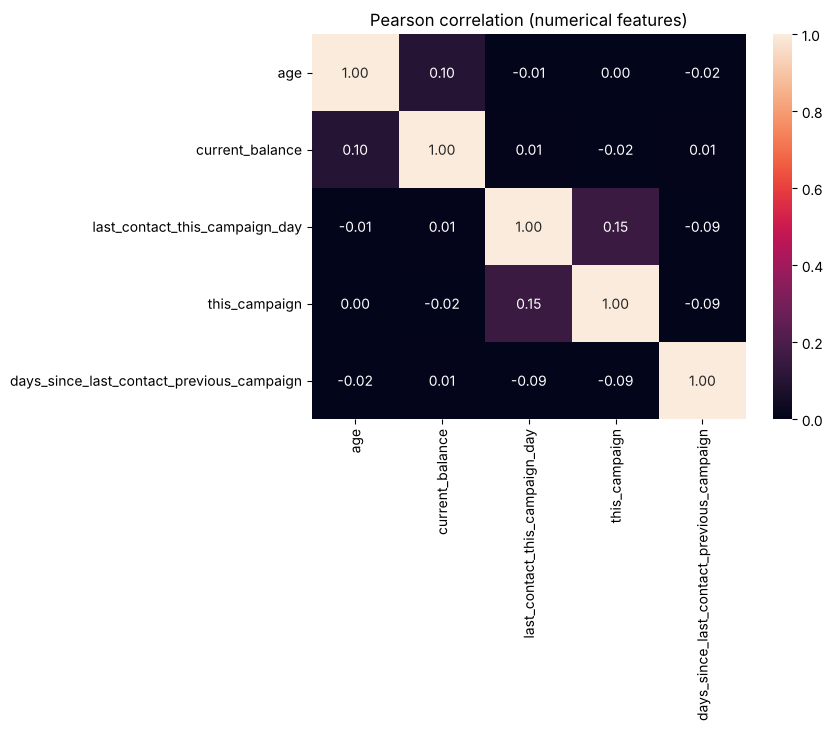

Max absolute correlation: 0.155 -> no multicollinearity (< 0.5)


In [11]:
pearson_cols = ["age", "current_balance", "last_contact_this_campaign_day", "this_campaign",
                "days_since_last_contact_previous_campaign"]
corr = train_df[pearson_cols].corr(method="pearson")
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="rocket", vmin=0, vmax=1)
plt.title("Pearson correlation (numerical features)")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).abs()
print("Max absolute correlation:", round(upper.max().max(), 3), "-> no multicollinearity (< 0.5)")

### 2.4 Feature transformation
* **`job`**: high cardinality → recategorised into `employed`, `unemployed`, `other`.
* **`contacted_during_previous_campaign`**: a numerical count grouped into **"Low"** (0 contacts, i.e. not contacted before) and **"High"** (≥ 1 contact). It is then treated as categorical, as shown in the poster's variable table.

In [12]:
EMPLOYED = ["management", "blue-collar", "technician", "admin.", "services",
            "self-employed", "entrepreneur", "housemaid"]

def transform_features(d):
    d = d.copy()
    d["job"] = np.where(d["job"].isin(EMPLOYED), "employed",
                        np.where(d["job"] == "unemployed", "unemployed", "other"))
    d["contacted_during_previous_campaign"] = np.where(
        d["contacted_during_previous_campaign"] > 0, "High", "Low")
    return d

train_df = transform_features(train_df)
test_df = transform_features(test_df)

if "contacted_during_previous_campaign" in numerical_features:
    numerical_features.remove("contacted_during_previous_campaign")
    categorical_features.append("contacted_during_previous_campaign")

print(train_df["job"].value_counts().to_dict())
print(train_df["contacted_during_previous_campaign"].value_counts().to_dict())
print("\nFinal numerical:", numerical_features)
print("Final categorical:", categorical_features)

{'employed': 35897, 'other': 3421, 'unemployed': 1210}
{'Low': 32507, 'High': 8021}

Final numerical: ['age', 'current_balance', 'last_contact_this_campaign_day', 'this_campaign', 'days_since_last_contact_previous_campaign']
Final categorical: ['job', 'married', 'education', 'arrears', 'housing', 'has_tv_package', 'last_contact', 'last_contact_this_campaign_month', 'outcome_previous_campaign', 'contacted_during_previous_campaign']


### 2.5 Skewness, kurtosis and log transformation of `current_balance`
`current_balance` contains negative values, so a **sign-preserving log transform** `sign(x)·log(1+|x|)` is used (a plain `log` is undefined for x ≤ 0).

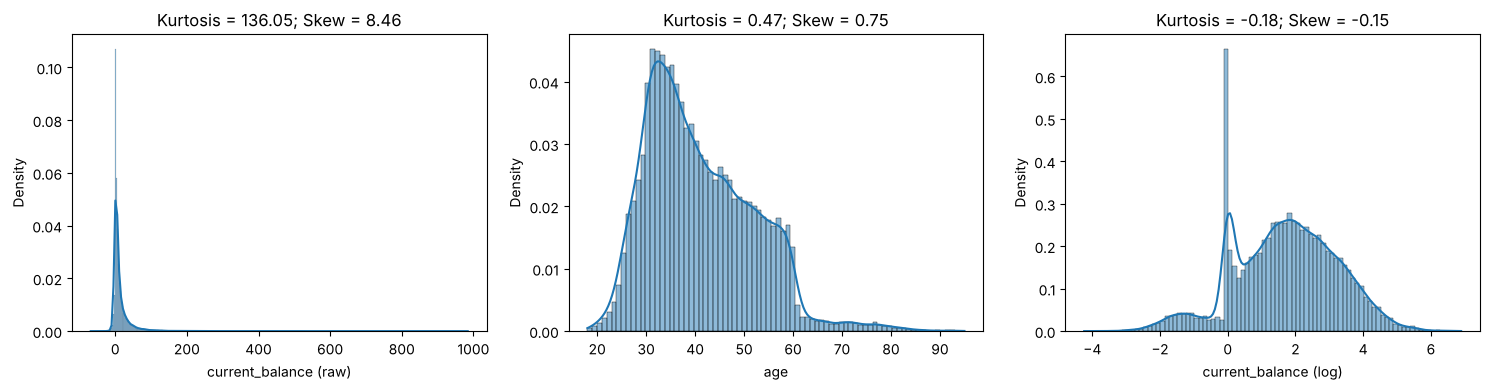

In [13]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (data, name) in zip(axes, [(train_df["current_balance"], "current_balance (raw)"),
                                   (train_df["age"], "age"),
                                   (signed_log(train_df["current_balance"]), "current_balance (log)")]):
    sns.histplot(data, kde=True, ax=ax, stat="density")
    ax.set_title(f"Kurtosis = {data.kurt():.2f}; Skew = {data.skew():.2f}")
    ax.set_xlabel(name)
plt.tight_layout(); plt.show()

`current_balance` is highly skewed with a long tail, so it is log-transformed. `age` has skew and kurtosis close to 0, so it is left unchanged.
The transform is placed **inside the modelling pipeline**, so it is applied consistently to whatever data the pipeline is fitted on or predicts.

### 2.6 Class imbalance

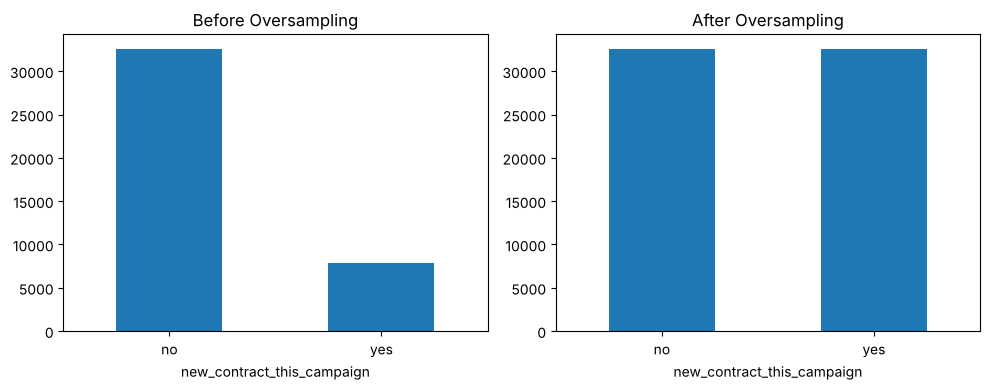

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
train_df[TARGET].map({0: "no", 1: "yes"}).value_counts().plot.bar(ax=axes[0], title="Before Oversampling")
X_tmp, y_tmp = RandomOverSampler(random_state=RANDOM_STATE).fit_resample(
    train_df[[TARGET]], train_df[TARGET])
y_tmp.map({0: "no", 1: "yes"}).value_counts().plot.bar(ax=axes[1], title="After Oversampling")
for ax in axes: ax.set_xlabel(TARGET); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

The majority class is "no", so the minority class is **randomly oversampled**. `RandomOverSampler` is a step in an `imblearn` pipeline, so it runs **only during fitting**. Each training fold (and the final training set) is balanced, while validation folds and the test set keep their real class distribution, which prevents leakage.

### 2.7 Pre-processing pipeline (log transform → scaling, one-hot encoding)

In [15]:
FEATURES = numerical_features + categorical_features
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

other_num = [c for c in numerical_features if c != "current_balance"]
num_log_pipe = Pipeline([("log", FunctionTransformer(signed_log, feature_names_out="one-to-one")), ("scale", StandardScaler())])

preprocessor = ColumnTransformer([
    ("balance", num_log_pipe, ["current_balance"]),
    ("num", StandardScaler(), other_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

def make_pipeline(model):
    return Pipeline([
        ("prep", preprocessor),
        ("oversample", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", model),
    ])

print(X_train.shape, X_test.shape)

(40528, 15) (10133, 15)


## 3. Model Building & Hyperparameter Selection – Nested K-Fold CV

* **Outer loop**: `KFold(k=5)` on the 80% training set (each fold is an 80% train / 20% validation split).
* **Inner loop**: `RandomizedSearchCV` on the outer training portion, using the poster's search spaces.
* The tuned model is scored on the outer validation fold (**accuracy**). The hyperparameters from the fold with the **highest accuracy** are selected for each algorithm.

| Model | Search space |
|---|---|
| Logistic Regression | `C: np.logspace(-4, 4, 20)`, `penalty: ['l1','l2']` |
| Decision Tree | `max_depth: [5,10]`, `min_samples_split: [2,5,10]`, `min_samples_leaf: [1,2,4]`, `criterion: ['gini','entropy']` |
| Neural Network | `hidden_layer_sizes: [(5,),(10,),(5,10),(10,5)]`, `max_iter: [100,200,500,1000]` |

*`N_ITER` and `INNER_CV` control the runtime; raise them for a more exhaustive search.*

In [16]:
models = {
    "Logistic Regression": (
        LogisticRegression(solver="liblinear", random_state=RANDOM_STATE),
        {"model__C": np.logspace(-4, 4, 20), "model__penalty": ["l1", "l2"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [5, 10], "model__min_samples_split": [2, 5, 10],
         "model__min_samples_leaf": [1, 2, 4], "model__criterion": ["gini", "entropy"]}),
    "Neural Network": (
        MLPClassifier(random_state=RANDOM_STATE),
        {"model__hidden_layer_sizes": [(5,), (10,), (5, 10), (10, 5)],
         "model__max_iter": [100, 200, 500, 1000]}),
}

OUTER_K = 5
INNER_CV = 3
N_ITER = 10
outer_cv = KFold(n_splits=OUTER_K, shuffle=True, random_state=RANDOM_STATE)

In [17]:
nested_results, best_params = {}, {}

for name, (estimator, space) in models.items():
    fold_scores = []
    for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), start=1):
        X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

        search = RandomizedSearchCV(make_pipeline(estimator), space, n_iter=N_ITER, cv=INNER_CV,
                                    scoring="accuracy", random_state=RANDOM_STATE, n_jobs=-1)
        search.fit(X_tr, y_tr)
        y_pred = search.predict(X_va)
        fold_scores.append({"fold": fold,
                            "accuracy": accuracy_score(y_va, y_pred),
                            "precision": precision_score(y_va, y_pred),
                            "recall": recall_score(y_va, y_pred),
                            "f1": f1_score(y_va, y_pred),
                            "params": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
        print(f"{name} | fold {fold} | acc={fold_scores[-1]['accuracy']:.4f} | {fold_scores[-1]['params']}")

    res = pd.DataFrame(fold_scores)
    nested_results[name] = res
    best_params[name] = res.loc[res["accuracy"].idxmax(), "params"]
    print(f"--> {name}: mean outer accuracy = {res['accuracy'].mean():.4f} ± {res['accuracy'].std():.4f}")
    print(f"--> best hyperparameters (highest-accuracy fold): {best_params[name]}\n")

Logistic Regression | fold 1 | acc=0.7471 | {'penalty': 'l1', 'C': np.float64(29.763514416313132)}


Logistic Regression | fold 2 | acc=0.7482 | {'penalty': 'l2', 'C': np.float64(3792.690190732246)}


Logistic Regression | fold 3 | acc=0.7530 | {'penalty': 'l1', 'C': np.float64(29.763514416313132)}


Logistic Regression | fold 4 | acc=0.7456 | {'penalty': 'l1', 'C': np.float64(29.763514416313132)}


Logistic Regression | fold 5 | acc=0.7403 | {'penalty': 'l1', 'C': np.float64(29.763514416313132)}
--> Logistic Regression: mean outer accuracy = 0.7468 ± 0.0046
--> best hyperparameters (highest-accuracy fold): {'penalty': 'l1', 'C': np.float64(29.763514416313132)}



Decision Tree | fold 1 | acc=0.8133 | {'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 10, 'criterion': 'entropy'}


... (5 outputs left out)

Neural Network | fold 2 | acc=0.7987 | {'max_iter': 200, 'hidden_layer_sizes': (5,)}


Neural Network | fold 3 | acc=0.7915 | {'max_iter': 100, 'hidden_layer_sizes': (5,)}


Neural Network | fold 4 | acc=0.7795 | {'max_iter': 500, 'hidden_layer_sizes': (10, 5)}


Neural Network | fold 5 | acc=0.7619 | {'max_iter': 100, 'hidden_layer_sizes': (5,)}
--> Neural Network: mean outer accuracy = 0.7849 ± 0.0146
--> best hyperparameters (highest-accuracy fold): {'max_iter': 200, 'hidden_layer_sizes': (5,)}



In [18]:
summary = pd.DataFrame({
    name: {"mean accuracy": r["accuracy"].mean(), "std accuracy": r["accuracy"].std(),
           "mean precision": r["precision"].mean(), "mean recall": r["recall"].mean(),
           "mean f1": r["f1"].mean(), "best hyperparameters": best_params[name]}
    for name, r in nested_results.items()}).T
summary

,mean accuracy,std accuracy,mean precision,mean recall,mean f1,best hyperparameters
Logistic Regression,0.746841,0.004602,0.406154,0.640387,0.497051,"{'penalty': 'l1', 'C': 29.763514416313132}"
Decision Tree,0.80907,0.008172,0.510464,0.579683,0.542669,"{'min_samples_split': 5, 'min_samples_leaf': 2..."
Neural Network,0.784889,0.014628,0.464786,0.645448,0.539967,"{'max_iter': 200, 'hidden_layer_sizes': (5,)}"


## 4. Model Evaluation – retrain on the full training set, evaluate on the unseen test set

In [19]:
final_models, test_rows = {}, []
for name, (estimator, _) in models.items():
    params = {f"model__{k}": v for k, v in best_params[name].items()}
    pipe = make_pipeline(estimator).set_params(**params)
    pipe.fit(X_train, y_train)
    final_models[name] = pipe
    y_pred = pipe.predict(X_test)
    test_rows.append({"Model": name,
                      "Accuracy": accuracy_score(y_test, y_pred),
                      "Precision": precision_score(y_test, y_pred),
                      "F1 score": f1_score(y_test, y_pred),
                      "Recall": recall_score(y_test, y_pred)})

test_results = pd.DataFrame(test_rows).set_index("Model").round(2)
test_results

,Accuracy,Precision,F1 score,Recall
Model,,,,
Logistic Regression,0.75,0.41,0.49,0.61
Decision Tree,0.82,0.54,0.55,0.55
Neural Network,0.79,0.47,0.54,0.63


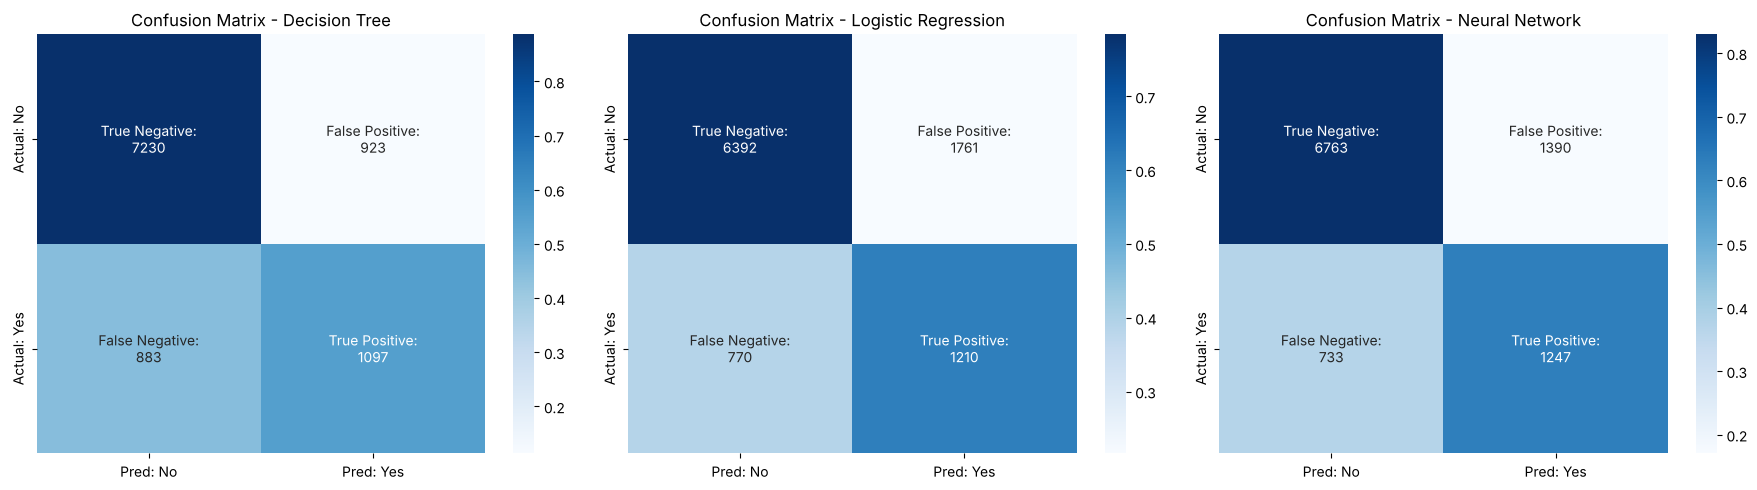

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, ["Decision Tree", "Logistic Regression", "Neural Network"]):
    cm = confusion_matrix(y_test, final_models[name].predict(X_test))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    labels = np.array([[f"True Negative:\n{cm[0,0]}", f"False Positive:\n{cm[0,1]}"],
                       [f"False Negative:\n{cm[1,0]}", f"True Positive:\n{cm[1,1]}"]])
    sns.heatmap(cm_norm, annot=labels, fmt="", cmap="Blues", ax=ax,
                xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
    ax.set_title(f"Confusion Matrix - {name}")
plt.tight_layout(); plt.show()

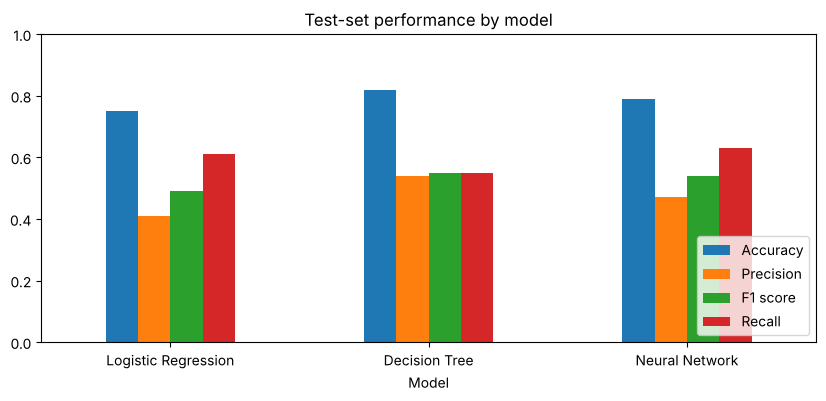

In [21]:
test_results.plot.bar(figsize=(10, 4), rot=0)
plt.title("Test-set performance by model"); plt.ylim(0, 1); plt.legend(loc="lower right"); plt.show()

## 5. Insights – feature importance

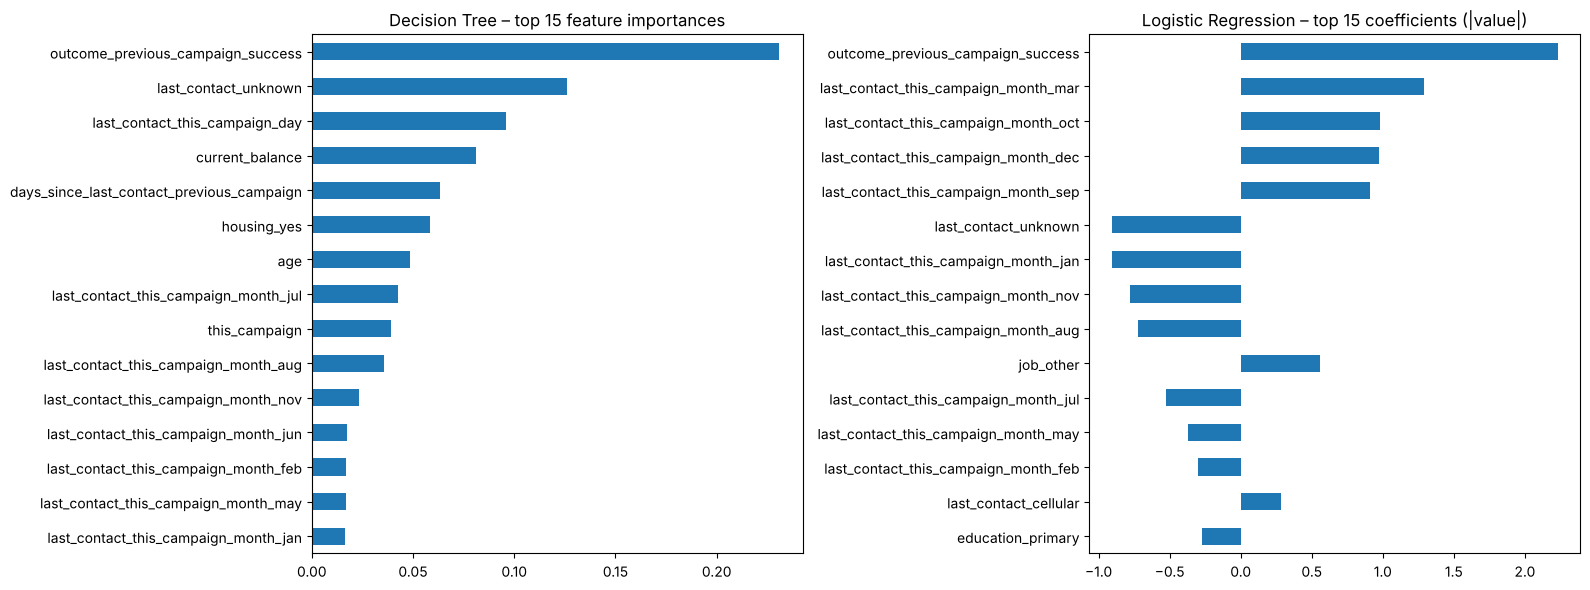

In [22]:
feat_names = final_models["Decision Tree"].named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__", 1)[1] for f in feat_names]

dt_imp = pd.Series(final_models["Decision Tree"].named_steps["model"].feature_importances_, index=feat_names)
lr_coef = pd.Series(final_models["Logistic Regression"].named_steps["model"].coef_[0], index=feat_names)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
dt_imp.sort_values().tail(15).plot.barh(ax=axes[0], title="Decision Tree – top 15 feature importances")
lr_coef.reindex(lr_coef.abs().sort_values().tail(15).index).plot.barh(
    ax=axes[1], title="Logistic Regression – top 15 coefficients (|value|)")
plt.tight_layout(); plt.show()

## 6. Discussion

* **Decision Tree** has the fewest false positives and the highest precision, but it misses more actual "yes" customers (more false negatives and lower recall).
* **Logistic Regression** predicts "yes" most often, which gives high recall but the most false positives and the lowest precision.
* **Neural Network** sits in between, with recall close to Logistic Regression and better accuracy and precision.

Missing a potential customer costs more than an extra call, so **recall is prioritised**. On that basis the poster selects the **Neural Network** as the most suitable model, even though the Decision Tree scores better on accuracy.
Exact numbers may vary slightly from the poster because of random seeds and the random-search sampling.

**References**
[1] J. Brownlee, "Feature selection with real and categorical data," *Machine Learning Mastery*, 2020.
[2] Scikit-learn developers, *Scikit-learn: Machine Learning in Python*, v1.6.1.